## **Nama: SYAUQI ASADUL HAQ**
## **NIM: H061241052**

Snapshot tersimpan: [75, 125, 175]


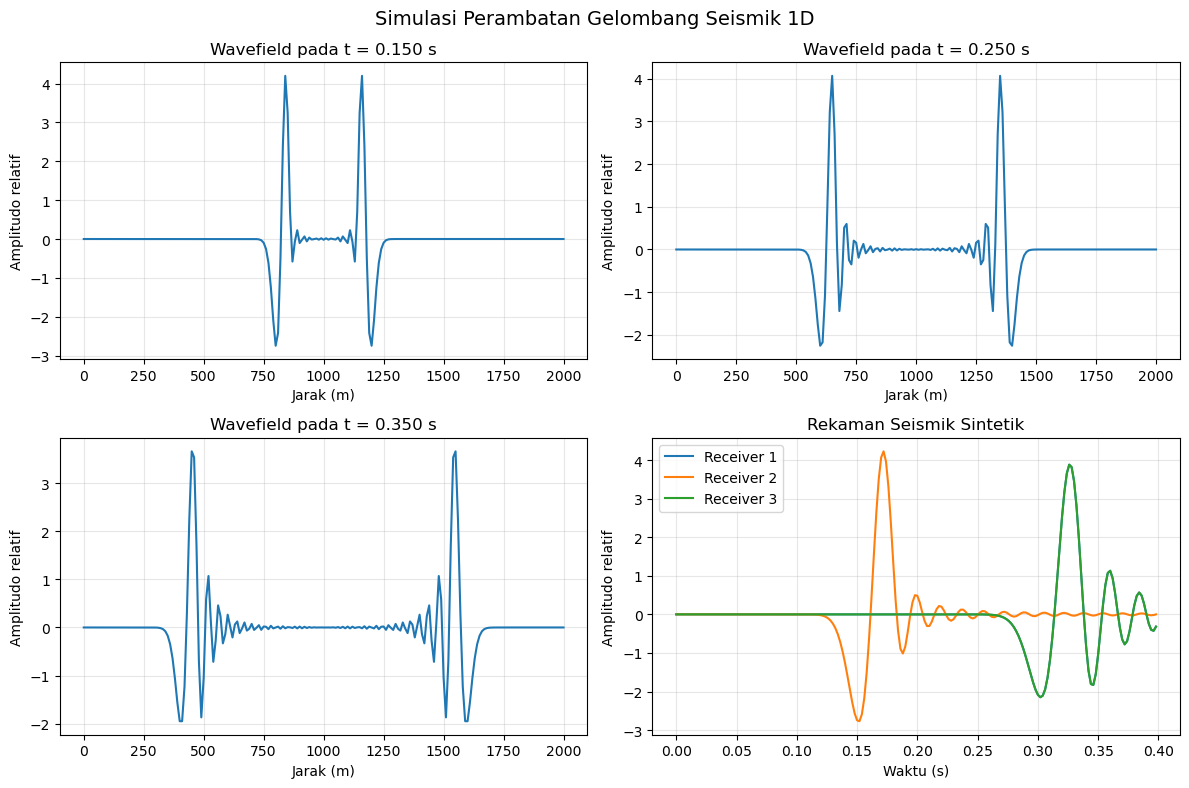


Simulasi selesai.
Jumlah grid: 201
Jumlah langkah waktu: 200
Kecepatan gelombang: 2000.0 m/s
Interval waktu: 0.002000 s
Jumlah receiver: 3
Durasi simulasi: 0.398000 s
Faktor CFL: 0.40


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# R-CS-004: Synthetic Seismic-Wave Reference Implementation
# Simulasi perambatan gelombang seismik 1D dalam medium homogen

# 1. Parameter model
nx = 201
nt = 200
dx = 10.0
velocity = 2000.0  # Kecepatan gelombang (m/s)
cfl = 0.4

dt = cfl * dx / velocity
x = np.arange(nx) * dx
time = np.arange(nt) * dt

# 2. Membuat sumber gelombang Ricker
f0 = 25.0
t0 = 1.5 / f0
tau = time - t0

source_wavelet = (
    (1 - 2 * (np.pi * f0 * tau) ** 2)
    * np.exp(-(np.pi * f0 * tau) ** 2)
)

# 3. Posisi sumber dan receiver
source_idx = nx // 2
receiver_indices = [50, 80, 150]
receiver_labels = ["Receiver 1", "Receiver 2", "Receiver 3"]

# 4. Inisialisasi medan gelombang
u_prev = np.zeros(nx)
u_curr = np.zeros(nx)
u_next = np.zeros(nx)

seismograms = np.zeros((len(receiver_indices), nt))

# Tentukan waktu snapshot sebelum simulasi
snapshot_steps = [75, 125, 175]
snapshots = {}

# 5. Simulasi perambatan gelombang
for it in range(nt):

    # Menghitung turunan ruang orde dua
    laplacian = np.zeros(nx)
    laplacian[1:-1] = (
        u_curr[2:]
        - 2 * u_curr[1:-1]
        + u_curr[:-2]
    )

    # Menghitung medan gelombang berikutnya
    u_next[:] = 0.0

    u_next[1:-1] = (
        2 * u_curr[1:-1]
        - u_prev[1:-1]
        + (velocity * dt / dx) ** 2 * laplacian[1:-1]
    )

    # Memasukkan sumber gelombang
    u_next[source_idx] += source_wavelet[it]

    # Merekam amplitudo pada receiver
    for ir, idx in enumerate(receiver_indices):
        seismograms[ir, it] = u_next[idx]

    # Menyimpan snapshot medan gelombang
    if it in snapshot_steps:
        snapshots[it] = u_next.copy()

    # Memperbarui medan gelombang
    u_prev, u_curr, u_next = u_curr, u_next, u_prev

# 6. Memeriksa snapshot
print("Snapshot tersimpan:", list(snapshots.keys()))

# 7. Membuat grafik hasil simulasi
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, step in zip(axes.flat[:3], snapshot_steps):
    ax.plot(x, snapshots[step])
    ax.set_title(f"Wavefield pada t = {time[step]:.3f} s")
    ax.set_xlabel("Jarak (m)")
    ax.set_ylabel("Amplitudo relatif")
    ax.grid(True, alpha=0.3)

# Grafik rekaman seismik
ax = axes.flat[3]

for i, label in enumerate(receiver_labels):
    ax.plot(time, seismograms[i], label=label)

ax.set_title("Rekaman Seismik Sintetik")
ax.set_xlabel("Waktu (s)")
ax.set_ylabel("Amplitudo relatif")
ax.legend()
ax.grid(True, alpha=0.3)

fig.suptitle(
    "Simulasi Perambatan Gelombang Seismik 1D",
    fontsize=14
)

plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    "grafik_hasil_simulasi.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 8. Menampilkan informasi simulasi
print("\nSimulasi selesai.")
print("Jumlah grid:", nx)
print("Jumlah langkah waktu:", nt)
print("Kecepatan gelombang:", velocity, "m/s")
print(f"Interval waktu: {dt:.6f} s")
print("Jumlah receiver:", len(receiver_indices))
print(f"Durasi simulasi: {time[-1]:.6f} s")
print(f"Faktor CFL: {velocity * dt / dx:.2f}")
